# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [3]:
df = pd.read_csv('AviationData_Cleaned.csv')
display(df.head())
print("Dataset shape:", df.shape)

C:\Users\lenovo x1 yoga\AppData\Local\Temp\ipykernel_27512\1952017023.py:1: DtypeWarning: Columns (0: Event.Id) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('AviationData_Cleaned.csv')


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Report.Status,Publication.Date,Total.Occupants,Fatal.Serious.Injuries,Fatal.Serious.Injury.Rate,Aircraft.Destroyed,Make_Model
0,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,NaN,NaN,IMC,Probable Cause,02-05-2011,NaN,NaN,NaN,1.0,PIPER | PA-28-140
1,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,NaN,4.0,VMC,Probable Cause,17-10-2016,NaN,NaN,NaN,NaN,DEHAVILLAND | DHC-6
2,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,NaN,1.0,VMC,Probable Cause,05-05-2011,NaN,NaN,NaN,0.0,BEECH | C35
3,20001214X45339,Accident,LAX84LA110,1983-12-22,"SANTA ROSA ISLAND, CA",United States,NaN,NaN,NaN,PRIVATE,...,NaN,1.0,VMC,Probable Cause,01-02-2016,NaN,NaN,NaN,0.0,CESSNA | 180K
4,20001214X38957,Accident,ATL84LA120,1984-03-14,"MYRTLE BEACH, SC",United States,NaN,NaN,CRE,GRAND STRAND,...,NaN,1.0,VMC,Probable Cause,24-09-2018,NaN,NaN,NaN,0.0,BEECH | 99


Dataset shape: (16549, 33)


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [4]:
# Separate smaller and larger airplanes using a 20-passenger threshold

# Ensure Total.Occupants is numeric
df['Total.Occupants'] = pd.to_numeric(
    df['Total.Occupants'], errors='coerce'
)

# Smaller airplanes: fewer than 20 occupants
small_airplanes = df[df['Total.Occupants'] < 20].copy()

# Larger airplanes: 20 or more occupants
large_airplanes = df[df['Total.Occupants'] >= 20].copy()

# Display the number of records in each group
print("Smaller airplanes:", small_airplanes.shape)
print("Larger airplanes:", large_airplanes.shape)

Smaller airplanes: (13607, 33)
Larger airplanes: (398, 33)


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

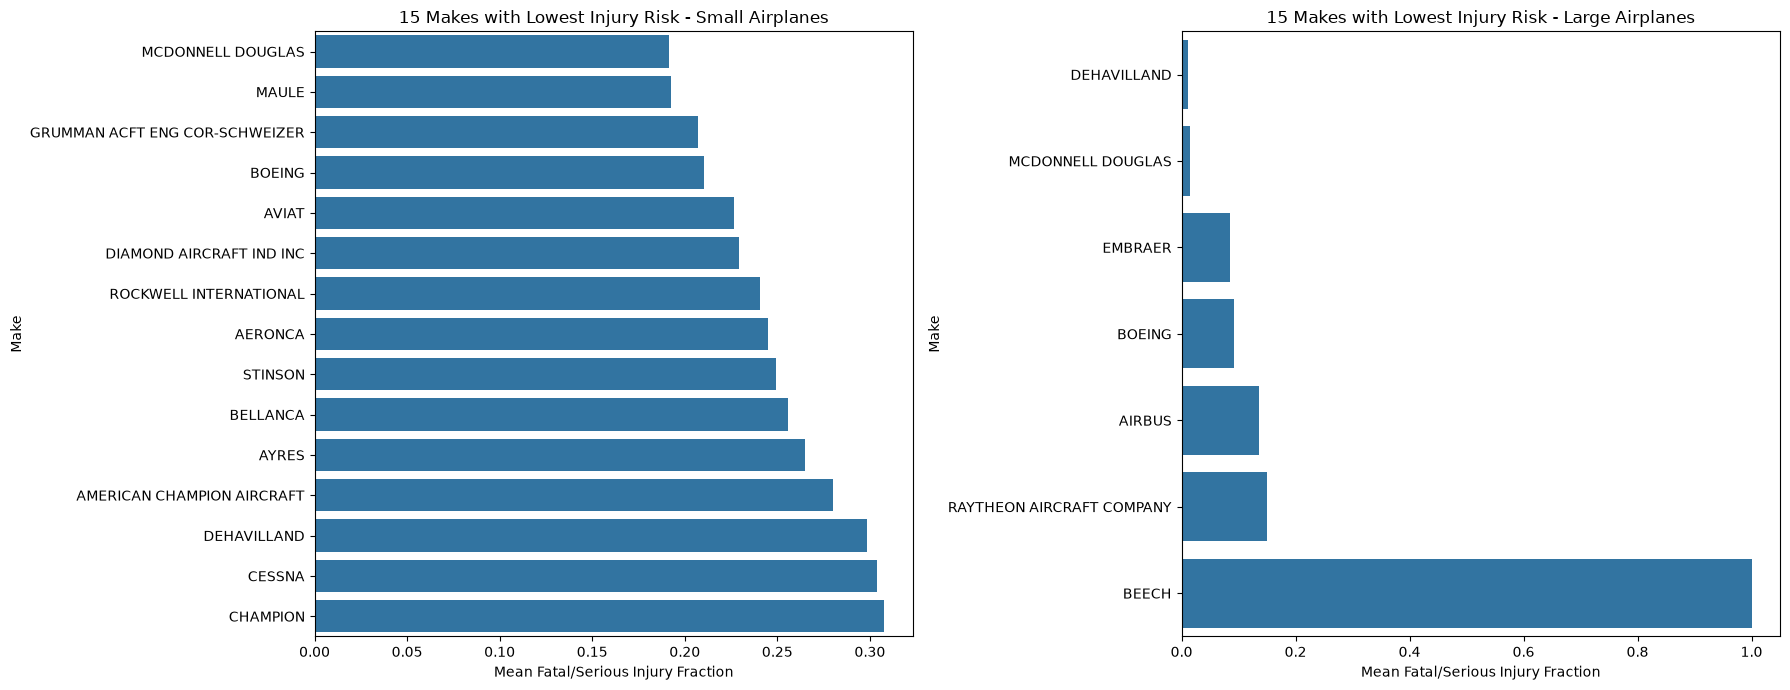

Small airplanes:


,Make,Fatal.Serious.Injury.Rate
0,MCDONNELL DOUGLAS,0.191327
1,MAULE,0.192593
2,GRUMMAN ACFT ENG COR-SCHWEIZER,0.206897
3,BOEING,0.210167
4,AVIAT,0.226496
5,DIAMOND AIRCRAFT IND INC,0.229167
6,ROCKWELL INTERNATIONAL,0.240566
7,AERONCA,0.245040
8,STINSON,0.249256
9,BELLANCA,0.255714


Large airplanes:


,Make,Fatal.Serious.Injury.Rate
0,DEHAVILLAND,0.011364
1,MCDONNELL DOUGLAS,0.015392
2,EMBRAER,0.085764
3,BOEING,0.092471
4,AIRBUS,0.135157
5,RAYTHEON AIRCRAFT COMPANY,0.150000
6,BEECH,1.000000


In [5]:
# Calculate mean fatal/seriously injured fraction for each Make
small_make_risk = (
    small_airplanes.groupby('Make')['Fatal.Serious.Injury.Rate']
    .mean()
    .dropna()
    .nsmallest(15)
    .reset_index()
)

large_make_risk = (
    large_airplanes.groupby('Make')['Fatal.Serious.Injury.Rate']
    .mean()
    .dropna()
    .nsmallest(15)
    .reset_index()
)

# Plot the results side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=small_make_risk,
    x='Fatal.Serious.Injury.Rate',
    y='Make',
    ax=axes[0]
)
axes[0].set_title('15 Makes with Lowest Injury Risk - Small Airplanes')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[0].set_ylabel('Make')

sns.barplot(
    data=large_make_risk,
    x='Fatal.Serious.Injury.Rate',
    y='Make',
    ax=axes[1]
)
axes[1].set_title('15 Makes with Lowest Injury Risk - Large Airplanes')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[1].set_ylabel('Make')

plt.tight_layout()
plt.show()

# Display the results
print("Small airplanes:")
display(small_make_risk)

print("Large airplanes:")
display(large_make_risk)

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

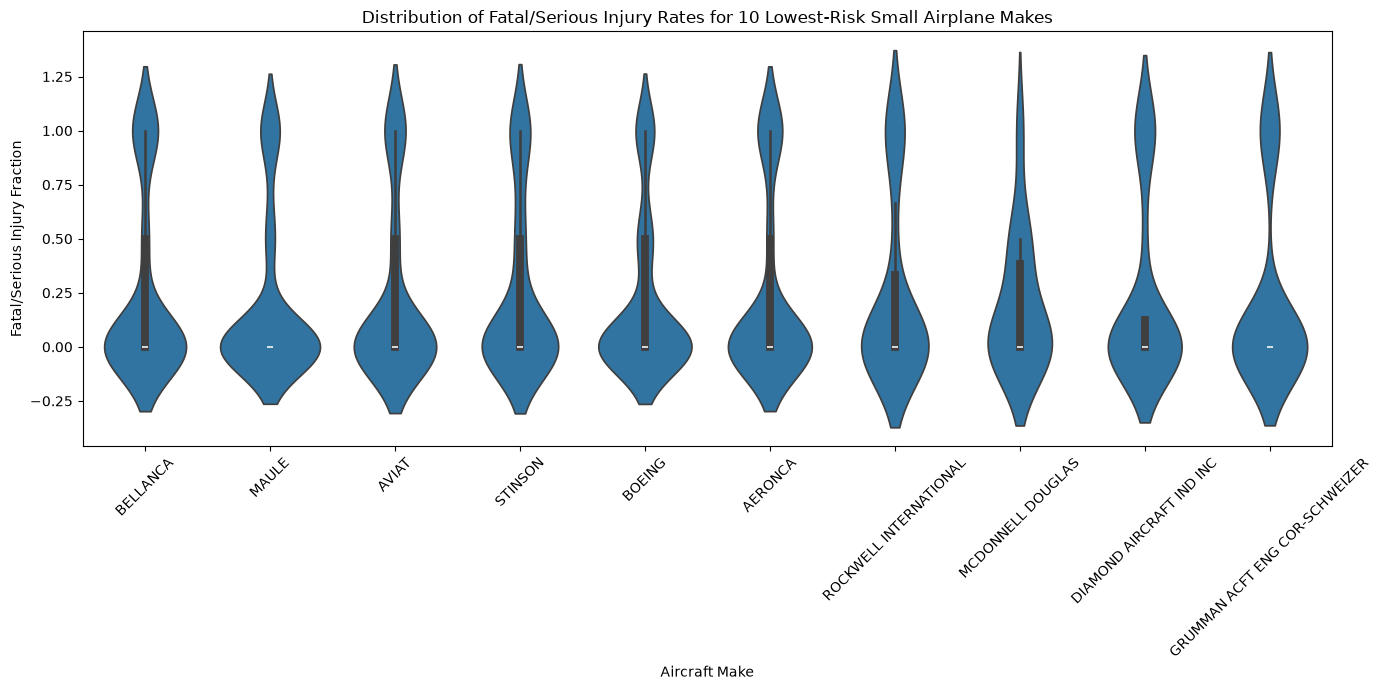

In [6]:
# Identify the 10 small-airplane makes with the lowest mean injury rates
top_10_small_makes = (
    small_airplanes.groupby('Make')['Fatal.Serious.Injury.Rate']
    .mean()
    .dropna()
    .nsmallest(10)
    .index
)

# Filter the data to include only those 10 makes
small_makes_data = small_airplanes[
    small_airplanes['Make'].isin(top_10_small_makes)
].dropna(subset=['Fatal.Serious.Injury.Rate'])

# Plot the distribution using a violin plot
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=small_makes_data,
    x='Make',
    y='Fatal.Serious.Injury.Rate'
)

plt.title('Distribution of Fatal/Serious Injury Rates for 10 Lowest-Risk Small Airplane Makes')
plt.xlabel('Aircraft Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

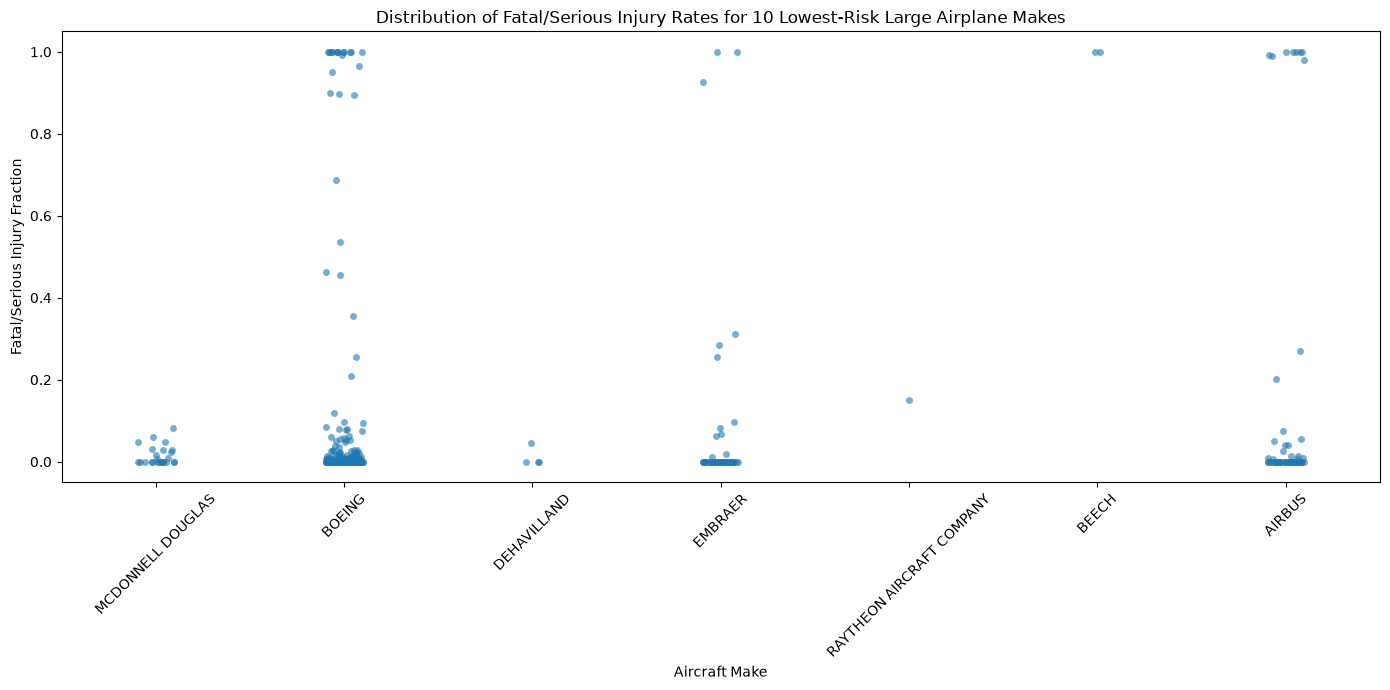

In [7]:
# Identify the 10 large-airplane makes with the lowest mean injury rates
top_10_large_makes = (
    large_airplanes.groupby('Make')['Fatal.Serious.Injury.Rate']
    .mean()
    .dropna()
    .nsmallest(10)
    .index
)

# Filter data to include only the 10 selected makes
large_makes_data = large_airplanes[
    large_airplanes['Make'].isin(top_10_large_makes)
].dropna(subset=['Fatal.Serious.Injury.Rate'])

# Plot the distribution using a strip plot
plt.figure(figsize=(14, 7))

sns.stripplot(
    data=large_makes_data,
    x='Make',
    y='Fatal.Serious.Injury.Rate',
    jitter=True,
    alpha=0.6
)

plt.title('Distribution of Fatal/Serious Injury Rates for 10 Lowest-Risk Large Airplane Makes')
plt.xlabel('Aircraft Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

15 Makes with the lowest destruction rates - Small Airplanes


,Make,Destruction Rate
0,GRUMMAN ACFT ENG COR-SCHWEIZER,0.017241
1,LUSCOMBE,0.017857
2,STINSON,0.017857
3,TAYLORCRAFT,0.027397
4,BELLANCA,0.034286
5,AMERICAN CHAMPION AIRCRAFT,0.040000
6,ERCOUPE,0.040816
7,MAULE,0.040936
8,AERONCA,0.041667
9,DIAMOND AIRCRAFT IND INC,0.055556


15 Makes with the lowest destruction rates - Large Airplanes


,Make,Destruction Rate
0,DEHAVILLAND,0.000000
1,RAYTHEON AIRCRAFT COMPANY,0.000000
2,EMBRAER,0.148148
3,BOEING,0.165289
4,MCDONNELL DOUGLAS,0.176471
5,AIRBUS,0.235294
6,BEECH,1.000000


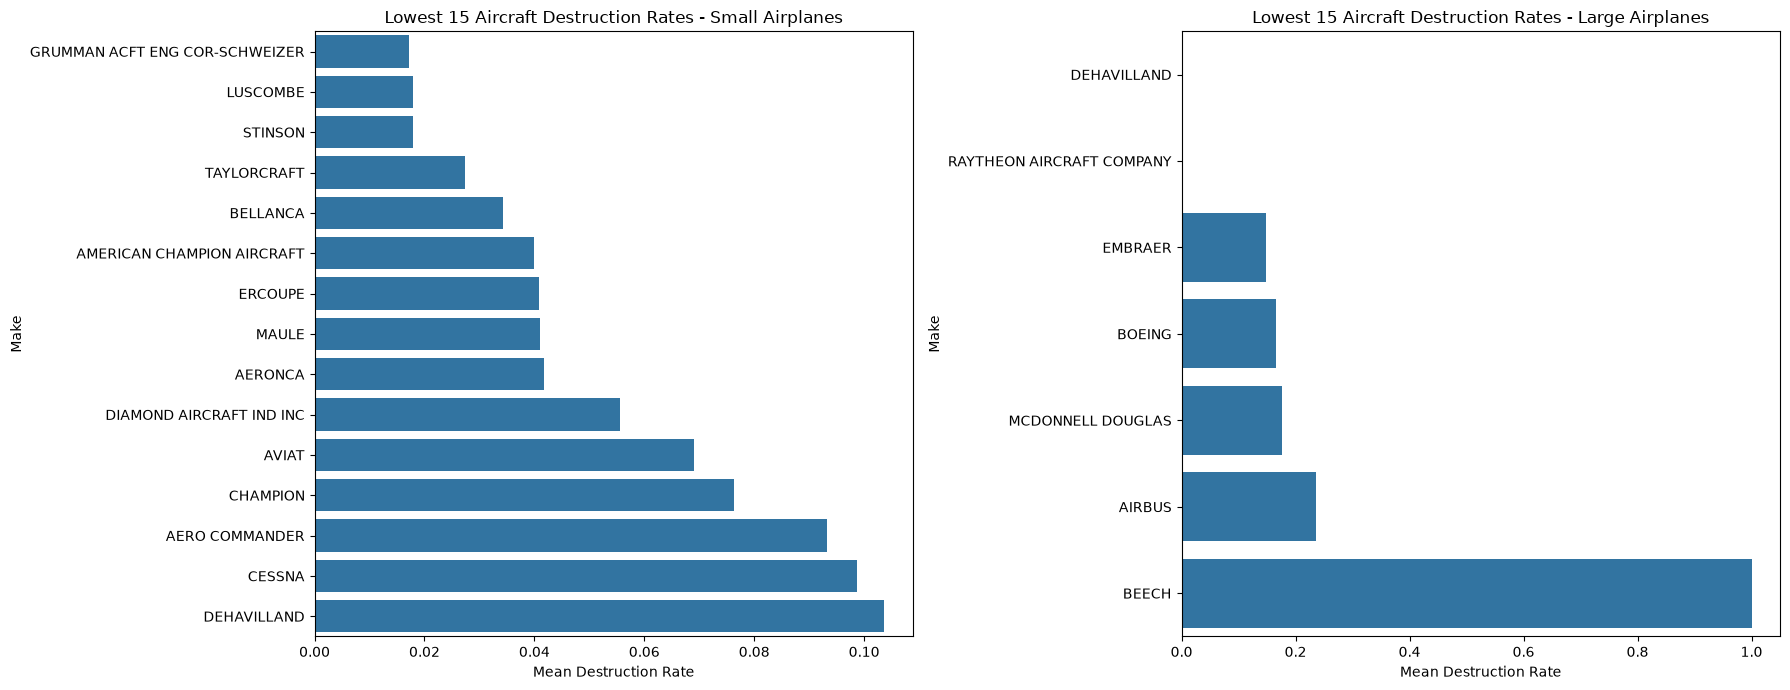

In [8]:
# Calculate aircraft destruction rate by Make for small airplanes
small_destruction = (
    small_airplanes.groupby('Make')['Aircraft.Destroyed']
    .mean()
    .dropna()
    .sort_values()
    .head(15)
    .reset_index(name='Destruction Rate')
)

# Calculate aircraft destruction rate by Make for large airplanes
large_destruction = (
    large_airplanes.groupby('Make')['Aircraft.Destroyed']
    .mean()
    .dropna()
    .sort_values()
    .head(15)
    .reset_index(name='Destruction Rate')
)

# Display results
print("15 Makes with the lowest destruction rates - Small Airplanes")
display(small_destruction)

print("15 Makes with the lowest destruction rates - Large Airplanes")
display(large_destruction)

# Plot results side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=small_destruction,
    x='Destruction Rate',
    y='Make',
    ax=axes[0]
)
axes[0].set_title('Lowest 15 Aircraft Destruction Rates - Small Airplanes')
axes[0].set_xlabel('Mean Destruction Rate')
axes[0].set_ylabel('Make')

sns.barplot(
    data=large_destruction,
    x='Destruction Rate',
    y='Make',
    ax=axes[1]
)
axes[1].set_title('Lowest 15 Aircraft Destruction Rates - Large Airplanes')
axes[1].set_xlabel('Mean Destruction Rate')
axes[1].set_ylabel('Make')

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

#The results show that there are certain makes of aircraft that had lower values for injuries and damage. 
# These makes could be considered.
    I would suggest using aircraft makes that had good results for both categories (less serious/fatal injuries and less damaged aircraft).
    However, it is also important to take into account how many accidents were recorded for each make as having a low value for a small amount of accidents may be misleading.
In conclusion, the plots can be used to compare aircraft safety. 
If more information was known e.g. flight time and conditions then better recommendations could be made.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

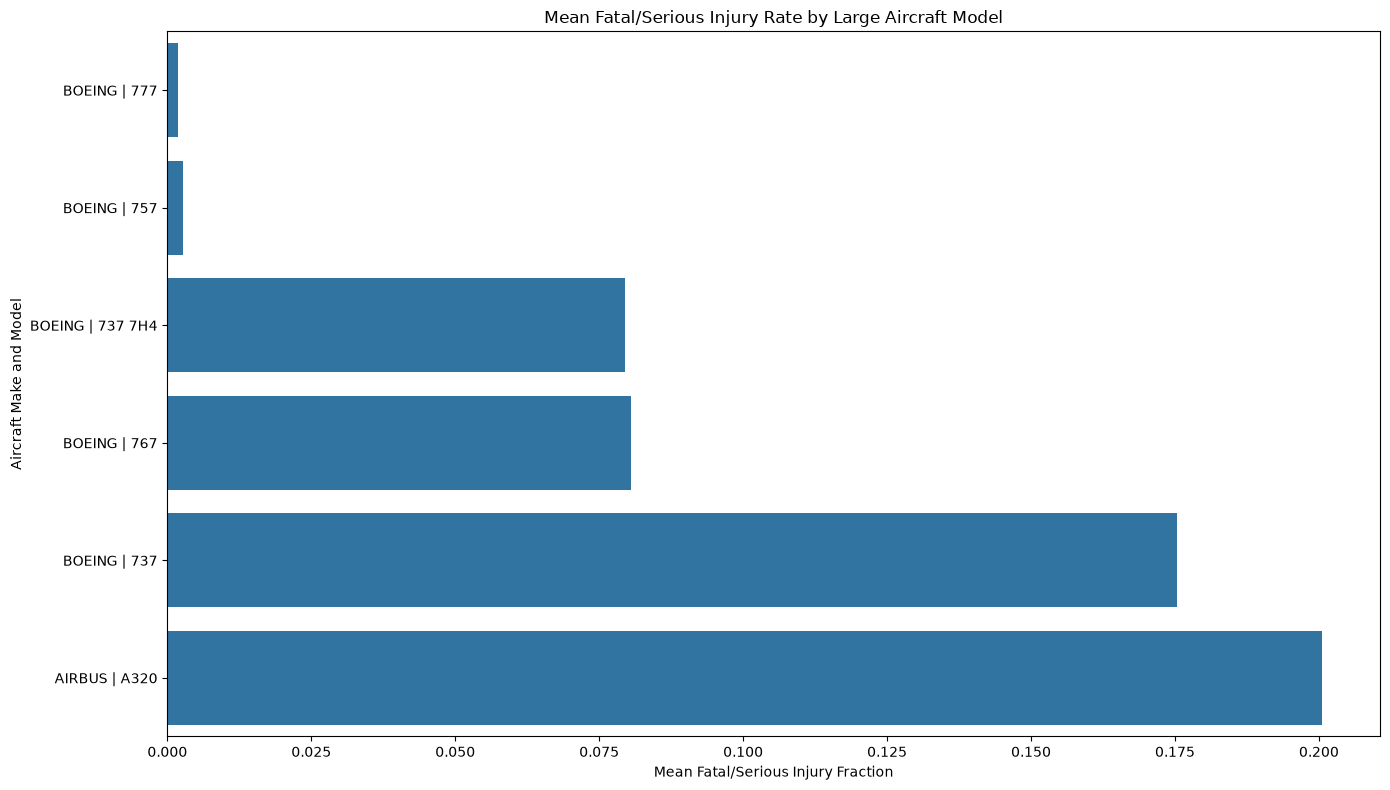

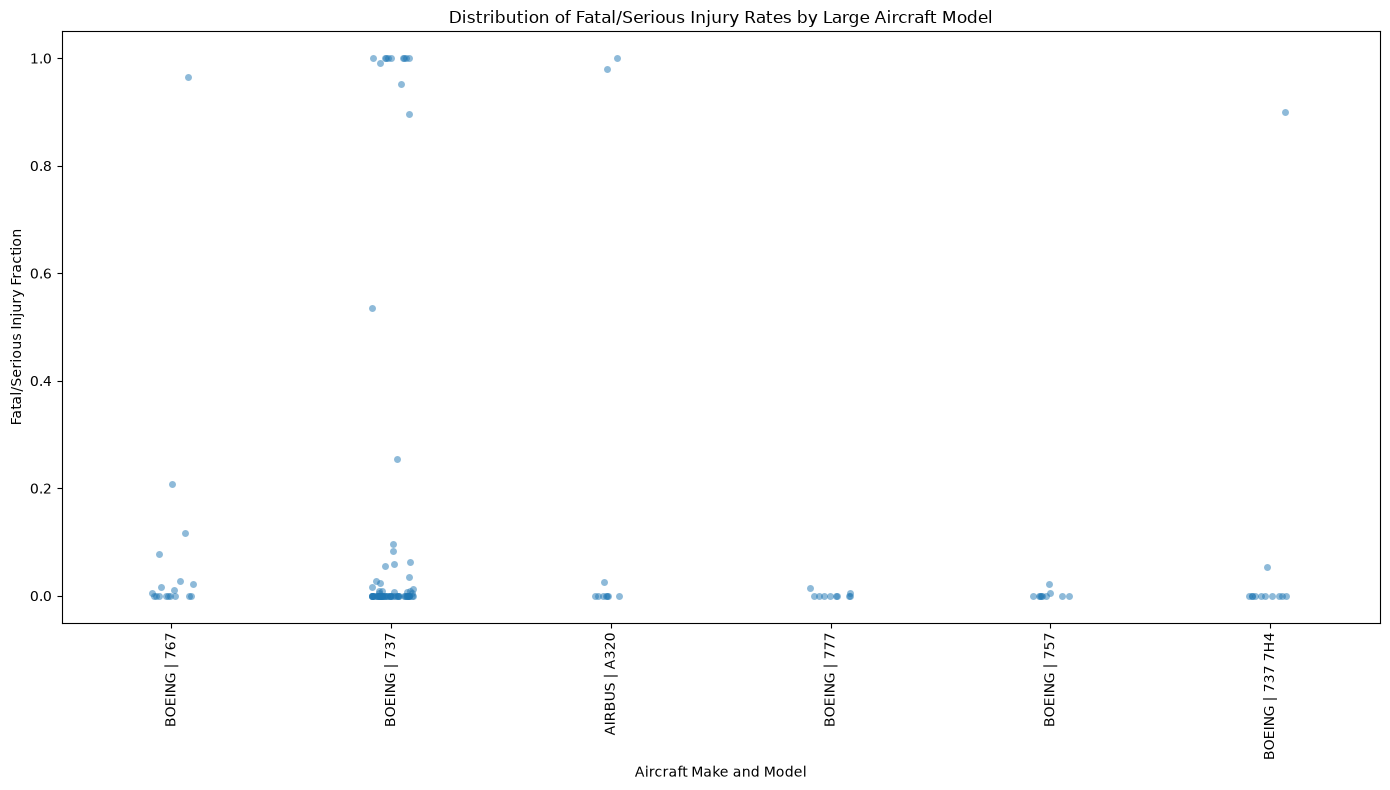

,Make_Model,Fatal.Serious.Injury.Rate
0,BOEING | 777,0.001826
1,BOEING | 757,0.002651
2,BOEING | 737 7H4,0.079474
3,BOEING | 767,0.080531
4,BOEING | 737,0.175361
5,AIRBUS | A320,0.200577


In [9]:
# Filter large airplanes to include only valid injury rates
large_data = large_airplanes.dropna(
    subset=['Make_Model', 'Fatal.Serious.Injury.Rate']
).copy()

# Keep only makes/models with at least 10 accident records
model_counts = large_data['Make_Model'].value_counts()
eligible_models = model_counts[model_counts >= 10].index

large_data = large_data[
    large_data['Make_Model'].isin(eligible_models)
]

# Calculate mean injury rate for each eligible model
large_model_means = (
    large_data.groupby('Make_Model')['Fatal.Serious.Injury.Rate']
    .mean()
    .sort_values()
    .reset_index()
)

# Plot mean fatal/serious injury fraction
plt.figure(figsize=(14, 8))
sns.barplot(
    data=large_model_means,
    x='Fatal.Serious.Injury.Rate',
    y='Make_Model'
)
plt.title('Mean Fatal/Serious Injury Rate by Large Aircraft Model')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Aircraft Make and Model')
plt.tight_layout()
plt.show()

# Plot distribution of individual injury rates using a stripplot
plt.figure(figsize=(14, 8))
sns.stripplot(
    data=large_data,
    x='Make_Model',
    y='Fatal.Serious.Injury.Rate',
    jitter=True,
    alpha=0.5
)
plt.title('Distribution of Fatal/Serious Injury Rates by Large Aircraft Model')
plt.xlabel('Aircraft Make and Model')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Display summary statistics
display(large_model_means)

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

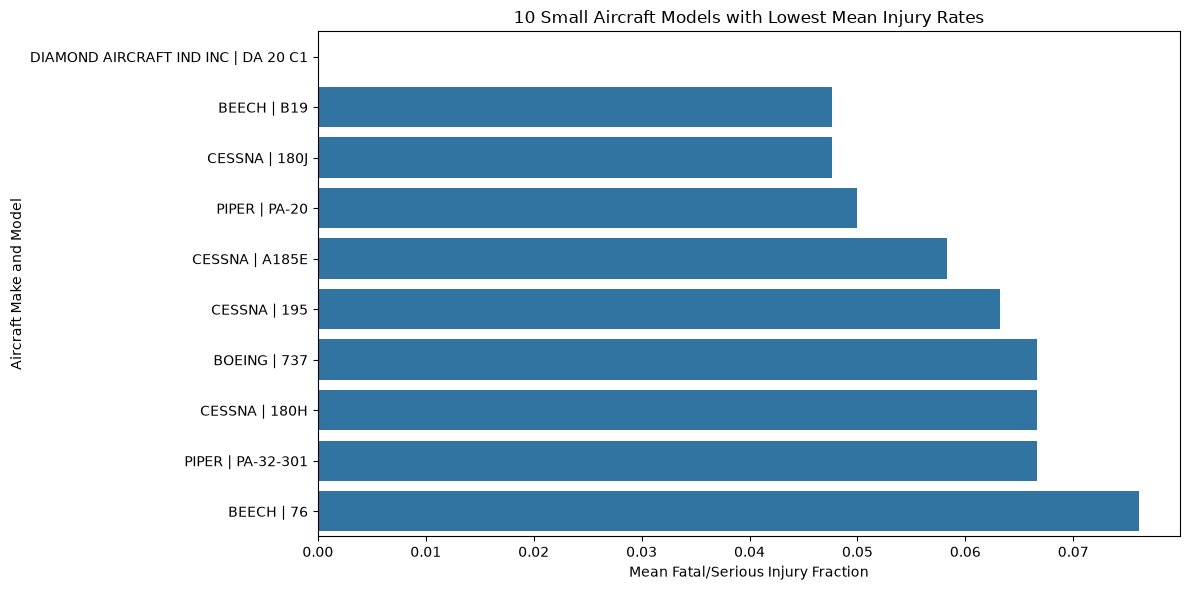

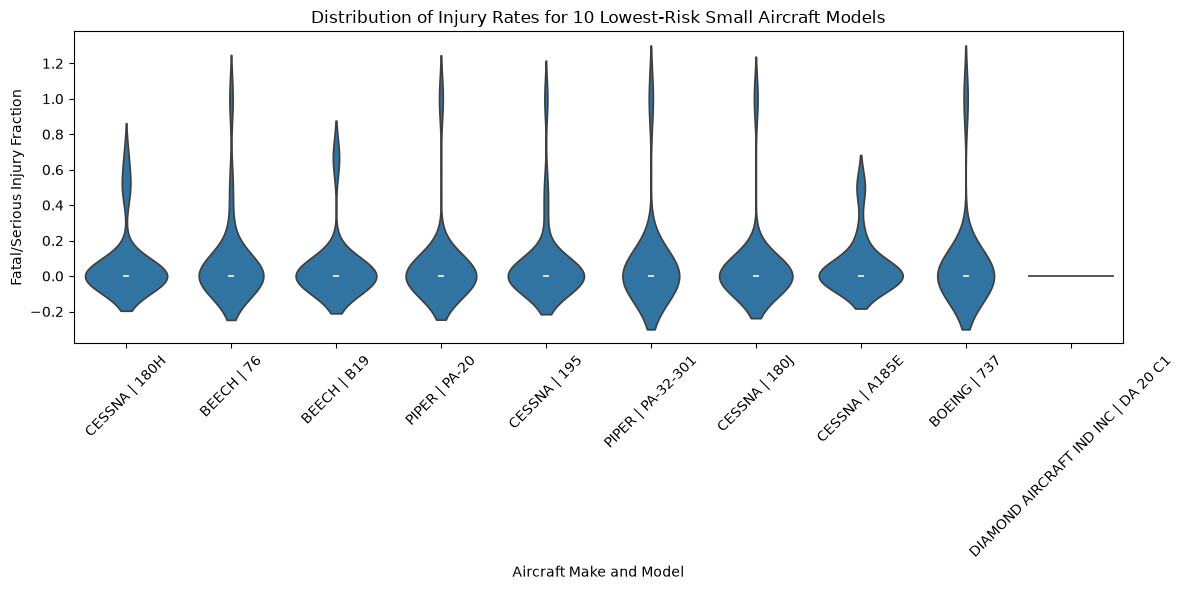

,Make_Model,Fatal.Serious.Injury.Rate
0,DIAMOND AIRCRAFT IND INC | DA 20 C1,0.000000
1,BEECH | B19,0.047619
2,CESSNA | 180J,0.047619
3,PIPER | PA-20,0.050000
4,CESSNA | A185E,0.058333
5,CESSNA | 195,0.063218
6,BOEING | 737,0.066667
7,CESSNA | 180H,0.066667
8,PIPER | PA-32-301,0.066667
9,BEECH | 76,0.076087


In [10]:
# Remove missing injury rates
small_data = small_airplanes.dropna(
    subset=['Make_Model', 'Fatal.Serious.Injury.Rate']
).copy()

# Keep makes/models with at least 10 accident records
model_counts = small_data['Make_Model'].value_counts()
eligible_models = model_counts[model_counts >= 10].index

small_data = small_data[
    small_data['Make_Model'].isin(eligible_models)
]

# Calculate mean injury rate and select the 10 lowest
small_model_means = (
    small_data.groupby('Make_Model')['Fatal.Serious.Injury.Rate']
    .mean()
    .nsmallest(10)
    .reset_index()
)

# Filter data to include only the 10 selected models
top_10_models = small_model_means['Make_Model']
small_data = small_data[
    small_data['Make_Model'].isin(top_10_models)
]

# Plot mean fatal/serious injury fractions
plt.figure(figsize=(12, 6))
sns.barplot(
    data=small_model_means,
    x='Fatal.Serious.Injury.Rate',
    y='Make_Model'
)
plt.title('10 Small Aircraft Models with Lowest Mean Injury Rates')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Aircraft Make and Model')
plt.tight_layout()
plt.show()

# Plot distribution of individual injury rates
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=small_data,
    x='Make_Model',
    y='Fatal.Serious.Injury.Rate'
)
plt.title('Distribution of Injury Rates for 10 Lowest-Risk Small Aircraft Models')
plt.xlabel('Aircraft Make and Model')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display summary statistics
display(small_model_means)

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

I can see from the results that some small and large planes have a better safety record. This is because they had less passengers and crew members that were seriously injured or died in an accident.

From the analysis it can be seen that you shouldn't just go for the size of the plane, but instead go for a model that consistently has a low injury rate. However, you should also consider how many accidents there were recorded for each model.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.


Safety summary by Weather.Condition:


,Weather.Condition,Accident_Count,Mean_Injury_Rate,Destruction_Rate
0,IMC,873,0.667828,0.376639
1,UNKNOWN,190,0.584693,0.448052
2,VMC,13979,0.268235,0.073459



Safety summary by Engine.Type:


,Engine.Type,Accident_Count,Mean_Injury_Rate,Destruction_Rate
0,RECIPROCATING,12743,0.293999,0.079304
3,TURBO PROP,877,0.343346,0.195376
1,TURBO FAN,364,0.135800,0.148936
5,UNKNOWN,68,0.384456,0.483333
2,TURBO JET,45,0.342057,0.343750


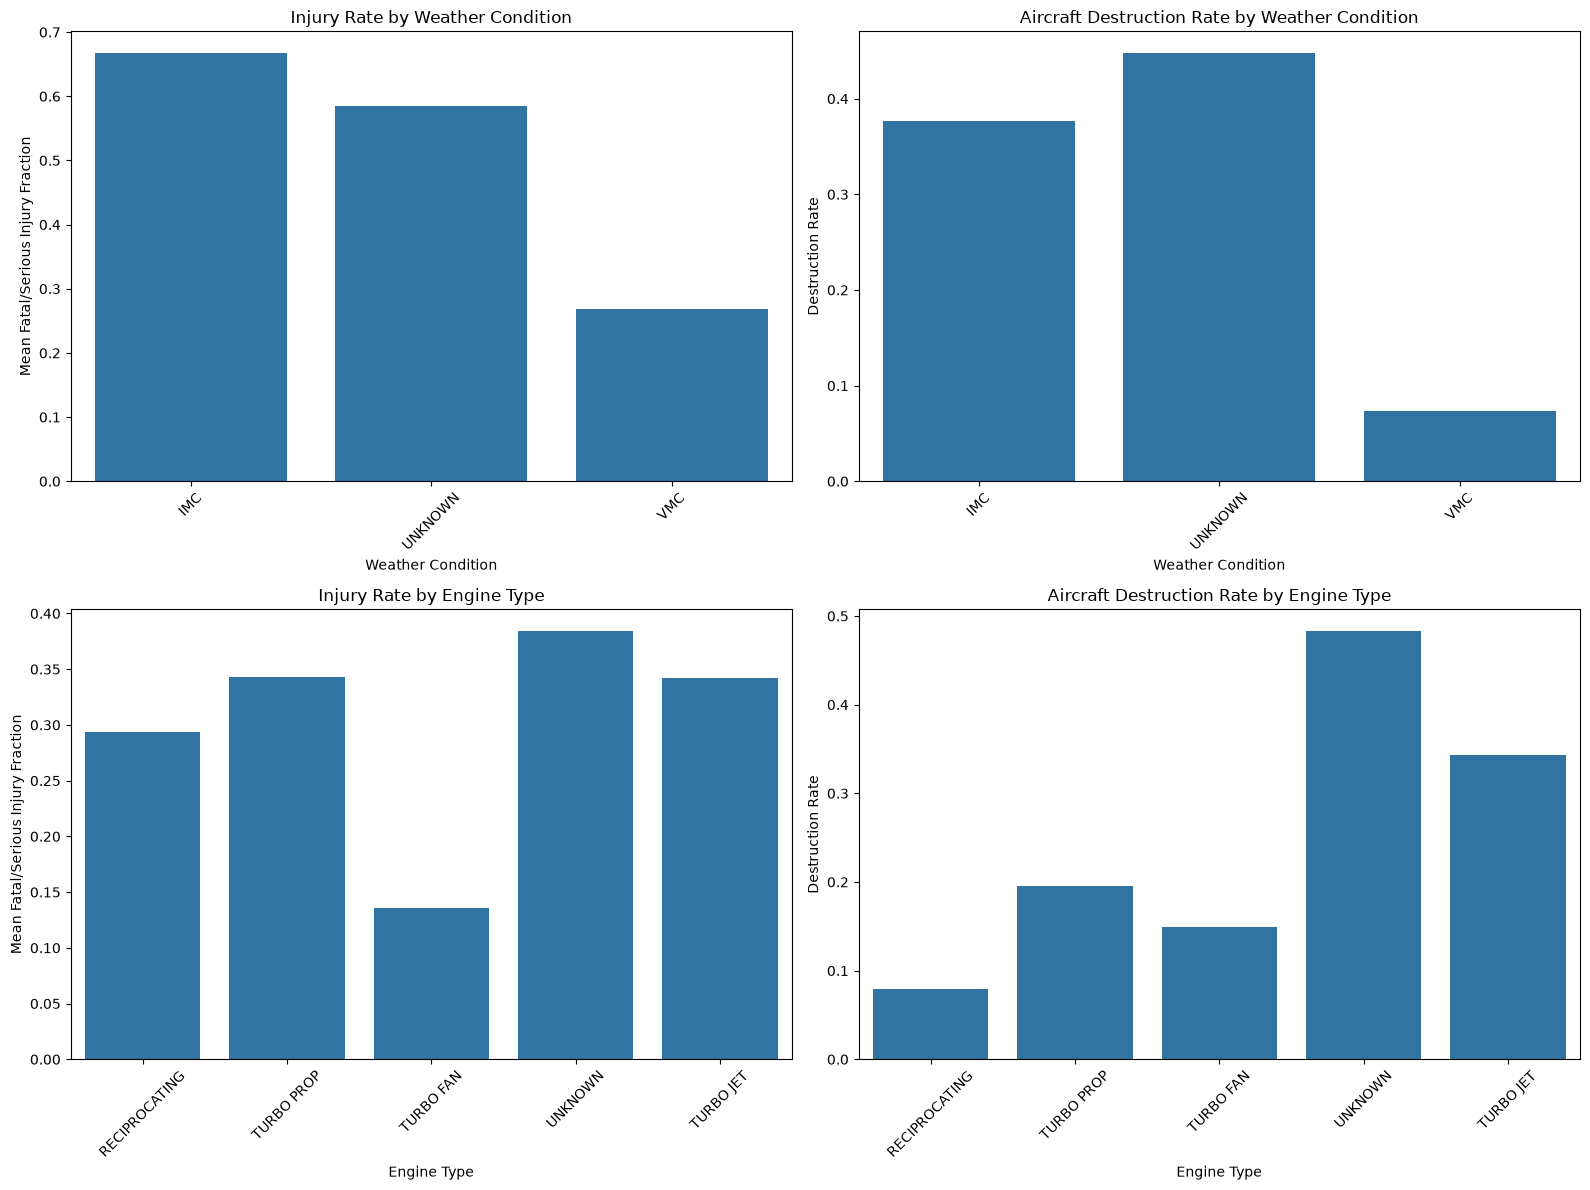

In [11]:
# Select the two factors for analysis
factors = ['Weather.Condition', 'Engine.Type']

# Ensure safety metrics are numeric
df['Fatal.Serious.Injury.Rate'] = pd.to_numeric(
    df['Fatal.Serious.Injury.Rate'], errors='coerce'
)
df['Aircraft.Destroyed'] = pd.to_numeric(
    df['Aircraft.Destroyed'], errors='coerce'
)

# Prepare summaries for each factor
summaries = {}

for factor in factors:
    data = df.dropna(subset=[factor]).copy()

    summary = (
        data.groupby(factor)
        .agg(
            Accident_Count=('Event.Date', 'count'),
            Mean_Injury_Rate=('Fatal.Serious.Injury.Rate', 'mean'),
            Destruction_Rate=('Aircraft.Destroyed', 'mean')
        )
        .reset_index()
    )

    # Keep categories with at least 10 accident records
    summary = summary[summary['Accident_Count'] >= 10]

    # For Engine Type, display the 10 most common categories
    if factor == 'Engine.Type':
        summary = summary.nlargest(10, 'Accident_Count')

    summaries[factor] = summary

    print(f"\nSafety summary by {factor}:")
    display(summary)

# Create four plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Weather: injury rate
sns.barplot(
    data=summaries['Weather.Condition'],
    x='Weather.Condition',
    y='Mean_Injury_Rate',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Injury Rate by Weather Condition')
axes[0, 0].set_xlabel('Weather Condition')
axes[0, 0].set_ylabel('Mean Fatal/Serious Injury Fraction')
axes[0, 0].tick_params(axis='x', rotation=45)

# Weather: destruction rate
sns.barplot(
    data=summaries['Weather.Condition'],
    x='Weather.Condition',
    y='Destruction_Rate',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Aircraft Destruction Rate by Weather Condition')
axes[0, 1].set_xlabel('Weather Condition')
axes[0, 1].set_ylabel('Destruction Rate')
axes[0, 1].tick_params(axis='x', rotation=45)

# Engine type: injury rate
sns.barplot(
    data=summaries['Engine.Type'],
    x='Engine.Type',
    y='Mean_Injury_Rate',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Injury Rate by Engine Type')
axes[1, 0].set_xlabel('Engine Type')
axes[1, 0].set_ylabel('Mean Fatal/Serious Injury Fraction')
axes[1, 0].tick_params(axis='x', rotation=45)

# Engine type: destruction rate
sns.barplot(
    data=summaries['Engine.Type'],
    x='Engine.Type',
    y='Destruction_Rate',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Aircraft Destruction Rate by Engine Type')
axes[1, 1].set_xlabel('Engine Type')
axes[1, 1].set_ylabel('Destruction Rate')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#Weather Conditions
From the analysis we can see that weather conditions could affect aircraft safety. Accidents which occur in bad weather can cause more serious injuries and damage to aircraft. Pilots will therefore need to be extra cautious when flying in difficult weather conditions.

#Engine Types
The results indicate that there are different levels of injuries and destruction to aircraft depending on the engine type. Certain engine types seem to have more favourable outcomes to accidents. However, we need to take into account how many accidents were recorded for each engine type.

#Overall
Both weather conditions and engine types are important factors to consider. The findings can help us understand what potential risk there is to aircraft safety but does not necessarily prove that it was a direct cause of the accidents/injuries.